# Figure 2: expression-space UMAPs

UMAPs of the matched scRNA-seq reference and one Xenium section before cleaning, after Syndri cleaning, and after SPLIT purification. Spatial panels use the same cells and genes. Each panel is embedded independently so that changes in expression-space structure remain visible.

In [1]:
from pathlib import Path
import warnings

import anndata as ad
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import to_hex
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import seaborn as sns

sc.settings.verbosity = 2
sns.set_theme(style="white", context="paper")

# The B1/B1_2 section matches the section used in Figure2_TranscriptsCellCrops.ipynb.
REFERENCE_PATH = Path('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/interim/single-cell/breast_cancer_chromium_genesubset.h5ad')
SPATIAL_PATH = Path('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/final/GSM9509174_breast_breast_B1_B1_3_rctd_annotated.h5ad')
OUTPUT_DIR = Path('/home/jwinchel/Syndri/figures/outputs')
OUTPUT_STEM = OUTPUT_DIR / 'Figure2_UMAPs'

REFERENCE_LAYER = 'SoupX'
REFERENCE_LABEL = 'cell_type'
SPATIAL_LABEL = 'harmony_cell_type'
PROBABILITY_LAYER = 'syndri_admix_probs_X'
SPLIT_LAYER = 'split_purified_counts_X'
TARGET_REMOVED_FRACTION = 0.30
MAX_SPATIAL_CELLS = None  # Use every cell from this one spatial slice.
N_PCS = 30
N_NEIGHBORS = 15
MIN_DIST = 0.4
RANDOM_STATE = 42
POINT_SIZE = 2.0
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load and validate inputs

The reference uses SoupX-corrected counts. Spatial labels and both purification inputs come from the final annotated Xenium object.

In [2]:
for path in (REFERENCE_PATH, SPATIAL_PATH):
    if not path.exists():
        raise FileNotFoundError(path)

reference = ad.read_h5ad(REFERENCE_PATH)
spatial = ad.read_h5ad(SPATIAL_PATH)

required = {
    'reference layer': (REFERENCE_LAYER, reference.layers),
    'reference label': (REFERENCE_LABEL, reference.obs),
    'spatial label': (SPATIAL_LABEL, spatial.obs),
    'Syndri probabilities': (PROBABILITY_LAYER, spatial.layers),
    'SPLIT counts': (SPLIT_LAYER, spatial.layers),
}
missing = [description for description, (key, container) in required.items() if key not in container]
if missing:
    raise KeyError(f'Missing required inputs: {missing}')

def feature_names(adata):
    if 'feature_name' in adata.var:
        return pd.Index(adata.var['feature_name'].astype(str))
    return pd.Index(adata.var_names.astype(str))

reference.var_names = feature_names(reference)
spatial.var_names = feature_names(spatial)
reference.var_names_make_unique()
spatial.var_names_make_unique()
common_genes = spatial.var_names[spatial.var_names.isin(reference.var_names)]
if len(common_genes) < 3:
    raise ValueError(f'Only {len(common_genes)} shared genes were found')
reference = reference[:, common_genes].copy()
spatial = spatial[:, common_genes].copy()

valid = spatial.obs[SPATIAL_LABEL].notna() & spatial.obs[SPATIAL_LABEL].astype(str).ne('nan')
spatial = spatial[valid].copy()
if MAX_SPATIAL_CELLS is not None and spatial.n_obs > MAX_SPATIAL_CELLS:
    rng = np.random.default_rng(RANDOM_STATE)
    keep = np.sort(rng.choice(spatial.n_obs, MAX_SPATIAL_CELLS, replace=False))
    spatial = spatial[keep].copy()

print(f'Reference: {reference.n_obs:,} cells x {reference.n_vars:,} shared genes')
print(f'Spatial:   {spatial.n_obs:,} cells x {spatial.n_vars:,} shared genes')
print(f'Spatial sample: {SPATIAL_PATH.name}')

Reference: 10,658 cells x 270 shared genes
Spatial:   108,069 cells x 270 shared genes
Spatial sample: GSM9509174_breast_breast_B1_B1_3_rctd_annotated.h5ad


## Construct the Syndri-cleaned matrix

Within each annotated cell type, the probability cutoff is chosen to remove the requested fraction of transcript count mass. This matches the cell-type-specific cleaning used for the Figure 2 expression summaries.

In [3]:
def as_csr(matrix):
    return matrix.tocsr().astype(np.float32) if sp.issparse(matrix) else sp.csr_matrix(np.asarray(matrix, dtype=np.float32))

def clean_by_cell_type(counts, probabilities, labels, target_fraction):
    counts = as_csr(counts)
    probabilities = as_csr(probabilities)
    if counts.shape != probabilities.shape:
        raise ValueError('Counts and Syndri probabilities must have identical shapes')
    if not 0 <= target_fraction <= 1:
        raise ValueError('TARGET_REMOVED_FRACTION must be between 0 and 1')

    cleaned = counts.copy()
    labels = np.asarray(labels).astype(str)
    records = []
    for label in pd.unique(labels):
        rows = np.flatnonzero(labels == label)
        block = counts[rows].tocoo()
        total = float(block.data.sum())
        if block.nnz == 0 or total == 0:
            records.append((label, np.inf, 0.0))
            continue
        p = np.asarray(probabilities[rows][block.row, block.col]).ravel()
        order = np.argsort(p)[::-1]
        cumulative = np.cumsum(block.data[order], dtype=np.float64)
        stop = min(np.searchsorted(cumulative, target_fraction * total, side='left'), len(order) - 1)
        threshold = float(p[order[stop]])
        records.append((label, threshold, float(block.data[p >= threshold].sum() / total)))

        block_clean = cleaned[rows].tolil()
        remove = p >= threshold
        for local_row, col in zip(block.row[remove], block.col[remove]):
            block_clean[local_row, col] = 0
        cleaned[rows] = block_clean.tocsr()

    cleaned.eliminate_zeros()
    thresholds = pd.DataFrame(records, columns=['cell_type', 'admix_prob_threshold', 'achieved_removed_fraction'])
    return cleaned, thresholds

raw_counts = as_csr(spatial.X)
syndri_counts, syndri_thresholds = clean_by_cell_type(
    raw_counts, spatial.layers[PROBABILITY_LAYER], spatial.obs[SPATIAL_LABEL], TARGET_REMOVED_FRACTION
)
split_counts = as_csr(spatial.layers[SPLIT_LAYER])
display(syndri_thresholds.sort_values('cell_type').reset_index(drop=True))

,cell_type,admix_prob_threshold,achieved_removed_fraction
0,"CD4-positive, alpha-beta memory T cell",0.996676,0.300004
1,capillary endothelial cell,0.990147,0.300002
2,classical monocyte,0.998805,0.300004
3,cytotoxic T cell,0.998168,0.300004
4,fibroblast of breast,0.993287,0.300006
5,fibroblast of lung,0.884267,0.300007
6,macrophage,0.993648,0.300001
7,malignant cell,0.785100,0.300000
8,mast cell,0.998843,0.300011
9,natural T-regulatory cell,0.999226,0.300009


## Compute independent UMAPs

All matrices receive the same normalization, log transform, PCA, neighbor-graph, and UMAP settings. The three spatial matrices retain an identical sampled cell set and gene order.

In [4]:
def compute_umap(template, matrix, label_key, title):
    current = ad.AnnData(
        X=as_csr(matrix),
        # Retain every observation-level annotation for downstream coloring.
        obs=template.obs.copy(),
        var=template.var.copy(),
    )
    current.obs['cell_type_plot'] = current.obs[label_key].astype(str)
    # sc.pp.normalize_total(current, target_sum=10_000)
    sc.pp.log1p(current)
    sc.pp.scale(current,max_value=None)
    n_comps = min(N_PCS, current.n_obs - 1, current.n_vars - 1)
    if n_comps < 2:
        raise ValueError(f'{title}: insufficient observations or genes for PCA')
    sc.pp.pca(current, n_comps=n_comps, random_state=RANDOM_STATE)
    sc.pp.neighbors(current, n_neighbors=min(N_NEIGHBORS, current.n_obs - 1), n_pcs=n_comps, random_state=RANDOM_STATE)
    sc.tl.umap(current, min_dist=MIN_DIST, random_state=RANDOM_STATE)
    return current

umap_adatas = {
    'scRNA-seq reference': compute_umap(reference, reference.layers[REFERENCE_LAYER], REFERENCE_LABEL, 'reference'),
    'Raw spatial': compute_umap(spatial, raw_counts, SPATIAL_LABEL, 'raw spatial'),
    'SPLIT-purified': compute_umap(spatial, split_counts, SPATIAL_LABEL, 'SPLIT-purified'),
    'Syndri-cleaned': compute_umap(spatial, syndri_counts, SPATIAL_LABEL, 'Syndri-cleaned'),
}
print('Finished:', ', '.join(umap_adatas))

computing PCA
    with n_comps=30


/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


    finished (0:00:01)
computing neighbors
    using 'X_pca' with n_pcs = 30
    finished (0:00:28)
computing UMAP
    finished (0:00:08)
computing PCA
    with n_comps=30


/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


    finished (0:00:02)
computing neighbors
    using 'X_pca' with n_pcs = 30
    finished (0:00:09)
computing UMAP
    finished (0:01:18)
computing PCA
    with n_comps=30


/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


    finished (0:00:04)
computing neighbors
    using 'X_pca' with n_pcs = 30
    finished (0:00:10)
computing UMAP
    finished (0:01:21)
computing PCA
    with n_comps=30


/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


    finished (0:00:02)
computing neighbors
    using 'X_pca' with n_pcs = 30
    finished (0:00:10)
computing UMAP
    finished (0:02:02)
Finished: scRNA-seq reference, Raw spatial, SPLIT-purified, Syndri-cleaned


## Plot and export Figure 2 panel

A single deterministic palette is shared across all panels; labels absent from an individual panel remain represented consistently.

In [5]:
umap_adatas

{'scRNA-seq reference': AnnData object with n_obs × n_vars = 10658 × 270
     obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'sample_id', 'percent_mt', 'percent_ribo', 'percent_hb', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'SCT_snn_res.0.5', 'SCT_snn_res.0.4', 'SCT_snn_res.2', 'donor_id', 'nCount_SoupX', 'nFeature_SoupX', 'Harmonised_Level4', 'Level3', 'Level2', 'Level1', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id', 'tissue_type', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'suspension_type', 'input_material', 'histology', 'sample_type', 'histology_immune', 'DV200_percent', 'block_age_months', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'cell_type_plot'
     var: 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype

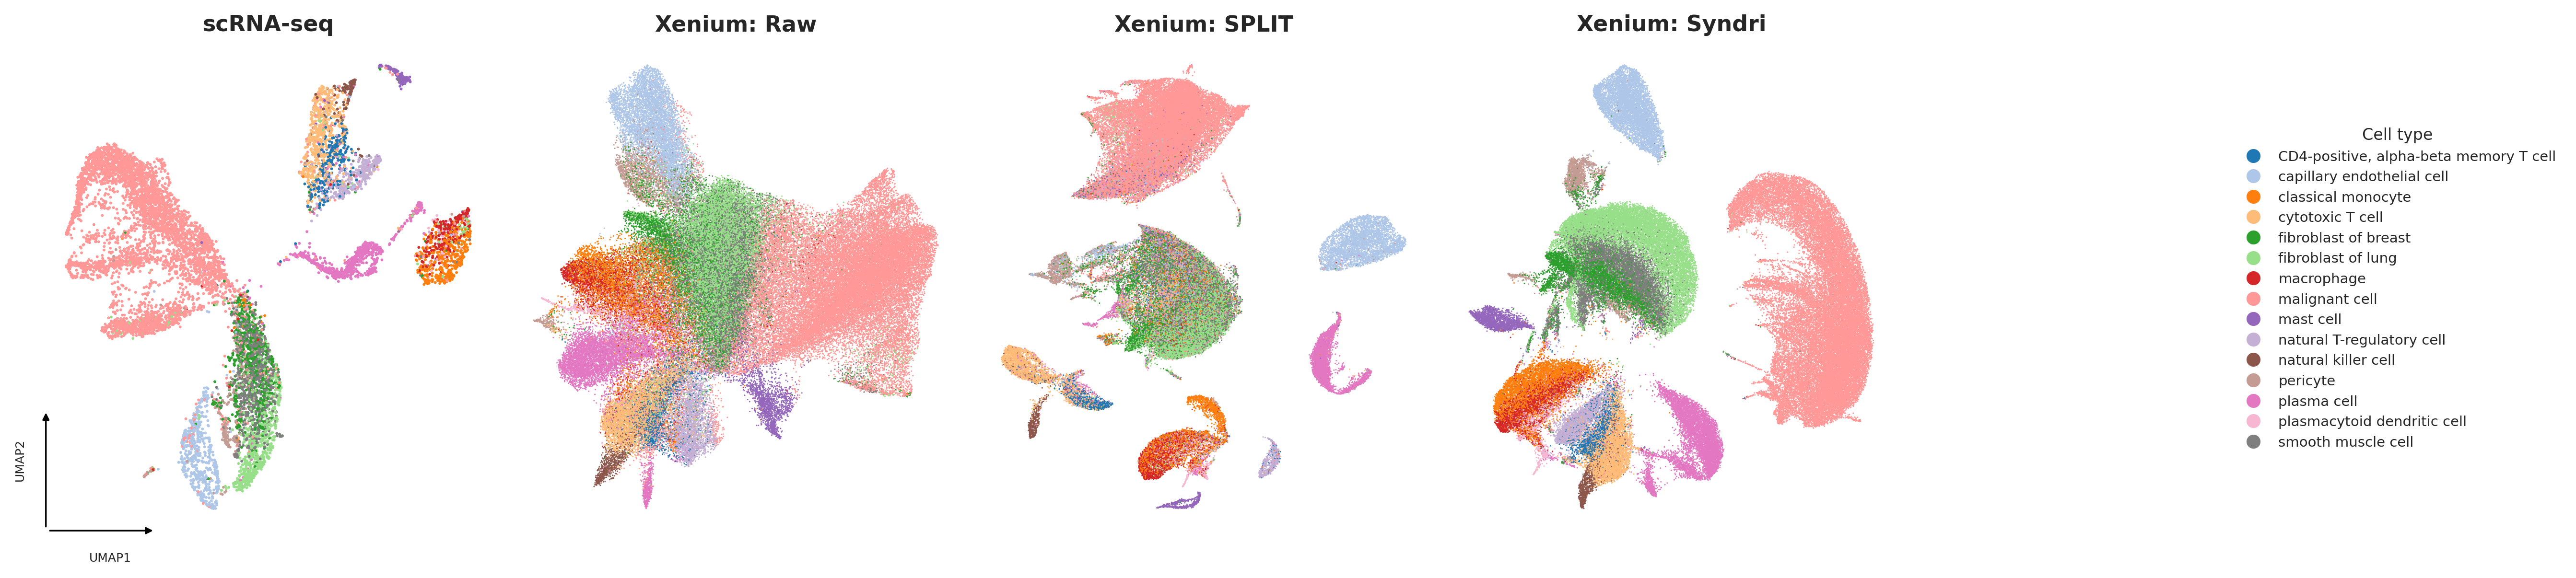

Saved /home/jwinchel/Syndri/figures/outputs/Figure2_UMAPs.pdf
Saved /home/jwinchel/Syndri/figures/outputs/Figure2_UMAPs.png


In [7]:

plot_order = [
    'scRNA-seq reference',
    'Raw spatial',
    'SPLIT-purified',
    'Syndri-cleaned',
]
missing_panels = [title for title in plot_order if title not in umap_adatas]
if missing_panels:
    raise KeyError(f'Missing UMAP panels: {missing_panels}')
plot_items = [(title, umap_adatas[title]) for title in plot_order]

categories = sorted({
    value
    for _, current in plot_items
    for value in current.obs['cell_type_plot'].dropna().astype(str).unique()
})
colors = sns.color_palette('tab20', n_colors=len(categories))
palette = dict(zip(categories, map(to_hex, colors)))
for _, current in plot_items:
    current.obs['cell_type_plot'] = pd.Categorical(current.obs['cell_type_plot'], categories=categories)

fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.1), dpi=300)
sizes = [2,0.5,0.5,0.5]
titles = ['scRNA-seq','Xenium: Raw','Xenium: SPLIT','Xenium: Syndri']
for i, (ax, (title, current)) in enumerate(zip(axes, plot_items)):
    # sc.pl.umap(
    #     current, color='cell_type_plot', palette=palette, title=title, ax=ax, show=False,
    #     frameon=False, legend_loc=None, size=POINT_SIZE, alpha=0.75, rasterized=True,
    # )
    sns.scatterplot(data=current.obs, x=current.obsm['X_umap'][:,0],y=current.obsm['X_umap'][:,1],hue='cell_type_plot',palette=palette,s=sizes[i],legend=False,ax=ax,edgecolor='none')
    ax.set_title(titles[i], fontsize=11, fontweight='bold')
    ax.axis('off')

# Small UMAP coordinate arrows on the first panel only.
axis_ax = axes[0]
origin = (0.00, 0.00)
axis_ax.annotate('', xy=(0.25, origin[1]), xytext=origin, xycoords='axes fraction', arrowprops=dict(arrowstyle='-|>', color='black', lw=0.8, mutation_scale=7))
axis_ax.annotate('', xy=(origin[0], 0.25), xytext=origin, xycoords='axes fraction', arrowprops=dict(arrowstyle='-|>', color='black', lw=0.8, mutation_scale=7))
axis_ax.text(0.145, -0.044, 'UMAP1', transform=axis_ax.transAxes, ha='center', va='top', fontsize=6)
axis_ax.text(-0.045, 0.145, 'UMAP2', transform=axis_ax.transAxes, ha='right', va='center', rotation=90, fontsize=6)

handles = [Line2D([0], [0], marker='o', linestyle='', markerfacecolor=palette[c], markeredgecolor='none', markersize=7, label=c) for c in categories]
fig.legend(handles=handles, labels=categories, title='Cell type', loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False, ncol=1, fontsize=7, title_fontsize=8)
fig.tight_layout(rect=(0, 0, 0.86, 1), w_pad=1.2)
fig.savefig(OUTPUT_STEM.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(OUTPUT_STEM.with_suffix('.png'), dpi=400, bbox_inches='tight')
plt.show()
print(f'Saved {OUTPUT_STEM.with_suffix(".pdf")}')
print(f'Saved {OUTPUT_STEM.with_suffix(".png")}')